# 01 · ERN simulation: latency jitter creates spurious theta


200 simulated error trials, each an ERN + Pe (two Gaussian components, **no oscillation**), with
* a Gaussian latency shift per trial (σ = 35 ms),
* log-normal amplitude variability (σ = 0.2),
* additive 1/f (pink) noise.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make the repo's `ern_theta` package importable

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from ern_theta import (align_trials, band_power, compute_tfr, regress_erp,
                       reinstate_lags, woody, woody_stochastic)
from ern_theta.plotting import (plot_lag_recovery, plot_residual_tfr,
                                plot_tf_decomposition, plot_trials)
from ern_theta.simulation import ERN, PE, gaussian, simulate_trials

SEED = 42
rng = np.random.default_rng(SEED)

# Epoch and time-frequency settings
sfreq = 500
tmin, tmax = -0.5, 1.0
times = np.linspace(tmin, tmax, int((tmax - tmin) * sfreq) + 1)
freqs = np.arange(1, 15, 1)  # Morlet wavelets with n_cycles = freqs / 2

# Simulation settings
n_trials = 200
jitter_sd = 0.035           # s
noise_amplitude = 3         # µV (scales unit-variance pink noise)
amplitude_jitter_sd = 0.2   # log-normal

# Stochastic Woody settings
N_STOCH_RUNS = 1000
WOODY_KW = dict(tol=0.1, max_it=100, xcorr_mthd='unbiased')

## 1. A single noiseless ERN + Pe and its evoked power

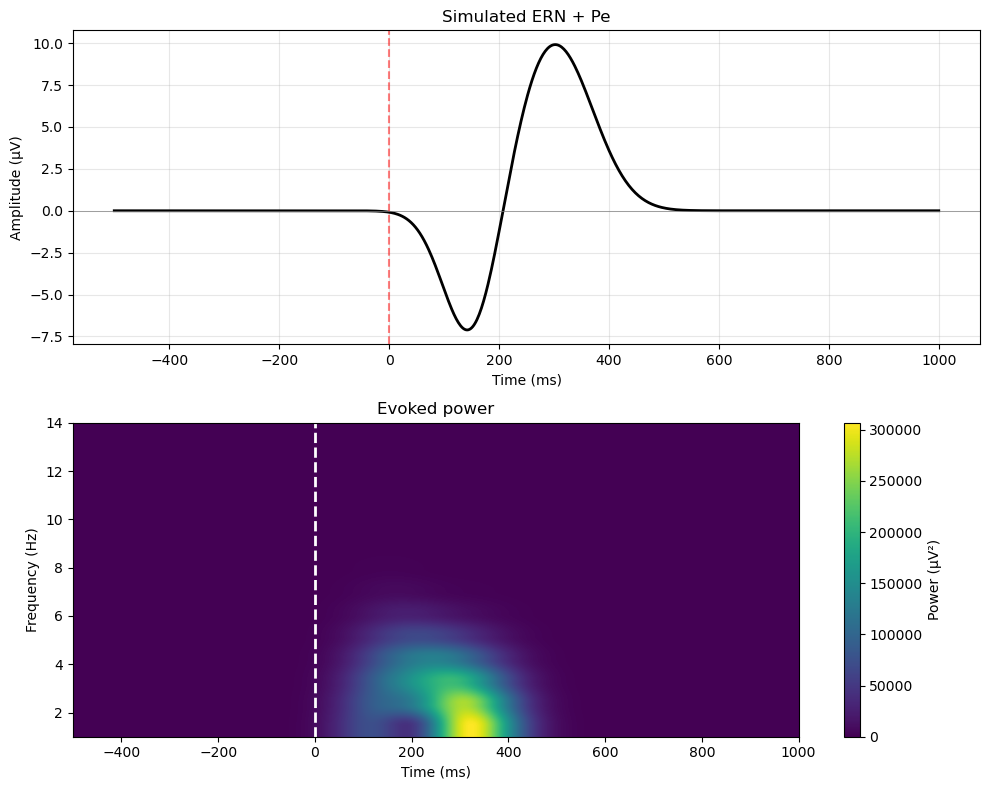

In [2]:
erp = gaussian(times, **ERN) + gaussian(times, **PE)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.plot(times * 1000, erp, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title('Simulated ERN + Pe')
ax1.grid(alpha=0.3)

im = ax2.imshow(compute_tfr(erp, freqs, sfreq), aspect='auto', origin='lower',
                extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]])
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Evoked power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')
plt.tight_layout()

## 2. Jittered, noisy single trials: classic induced power

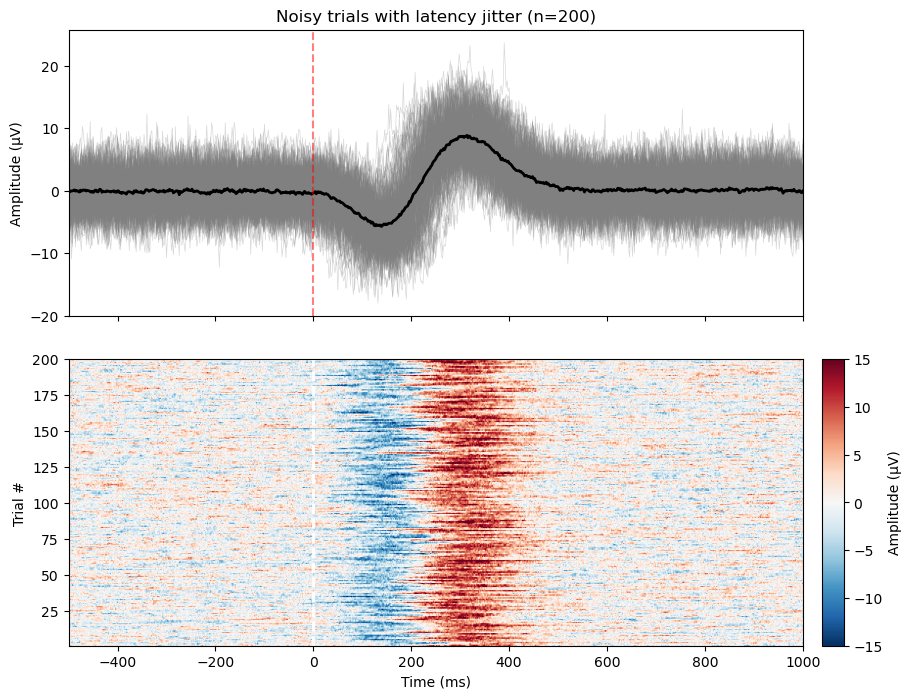

In [3]:
trials, true_jitters = simulate_trials(times, n_trials, rng, jitter_sd=jitter_sd,
                                      noise_amplitude=noise_amplitude,
                                      amplitude_jitter_sd=amplitude_jitter_sd)
true_lags = true_jitters * sfreq  # in samples

plot_trials(times, trials, f'Noisy trials with latency jitter (n={n_trials})');

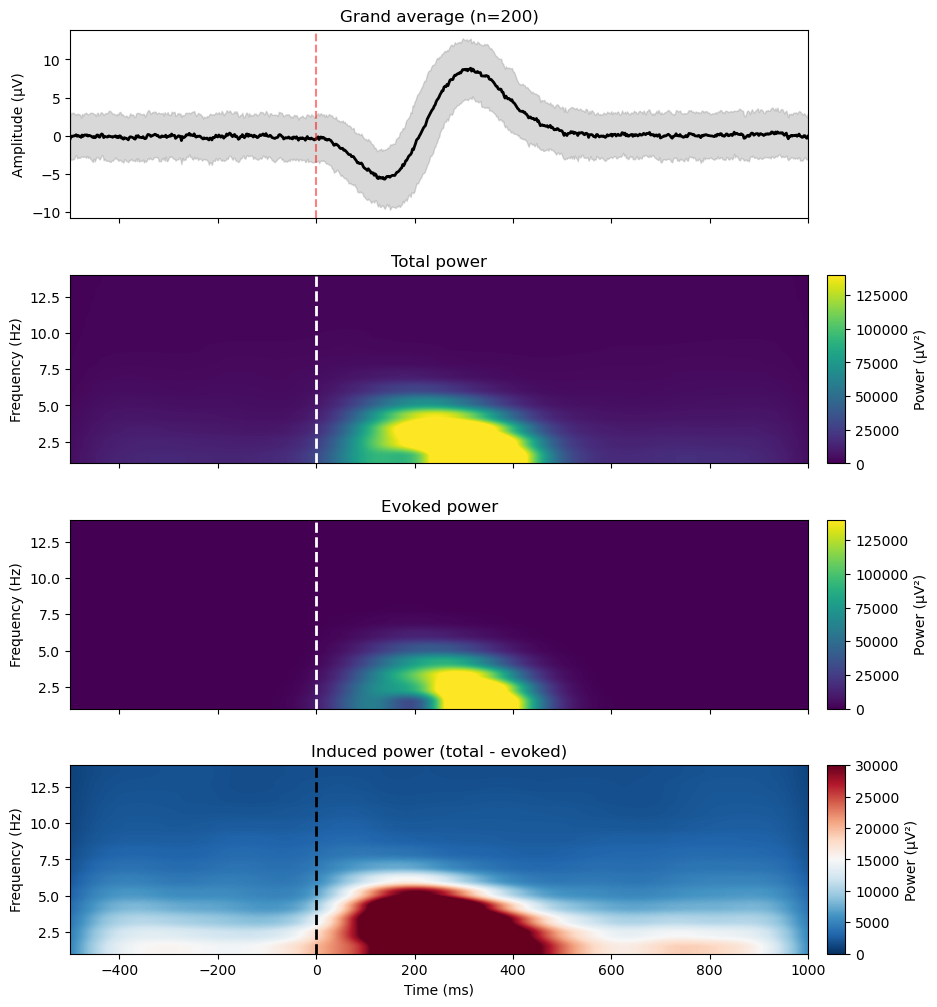

In [4]:
tfr_total = compute_tfr(trials, freqs, sfreq)
tfr_evoked = compute_tfr(trials.mean(axis=0), freqs, sfreq)
plot_tf_decomposition(times, freqs, trials, tfr_total, tfr_evoked);

## 3. Classic single-trial ERP regression

`trial = β₀ + β₁·ERP_avg + ε`, keep ε. Because the trials are jittered, the average ERP does not match any single trial, and the residuals still carry evoked activity → **spurious theta remains** (poster: *"Incorrect trials – ERP regressed out"*).

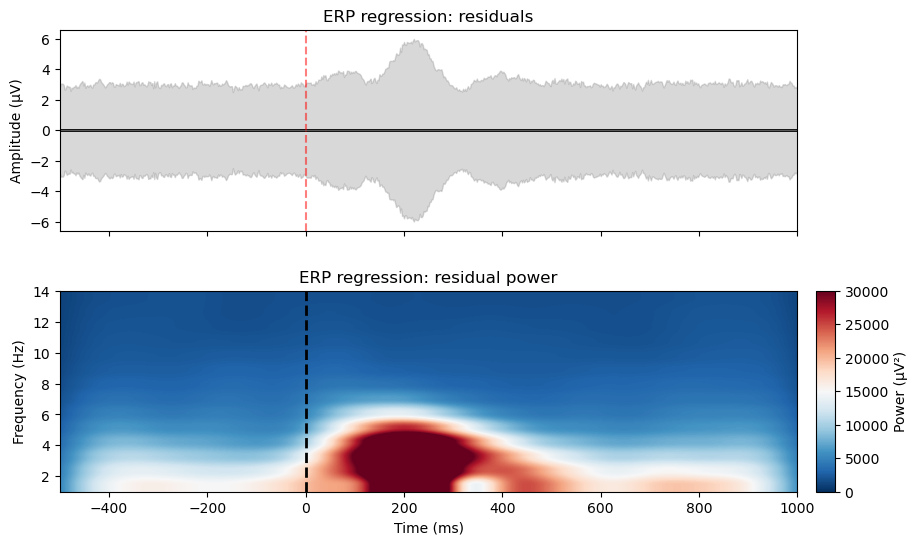

In [5]:
trials_regressed = regress_erp(trials, trials.mean(axis=0))
tfr_regressed = compute_tfr(trials_regressed, freqs, sfreq)
plot_residual_tfr(times, freqs, trials_regressed, tfr_regressed, 'ERP regression');

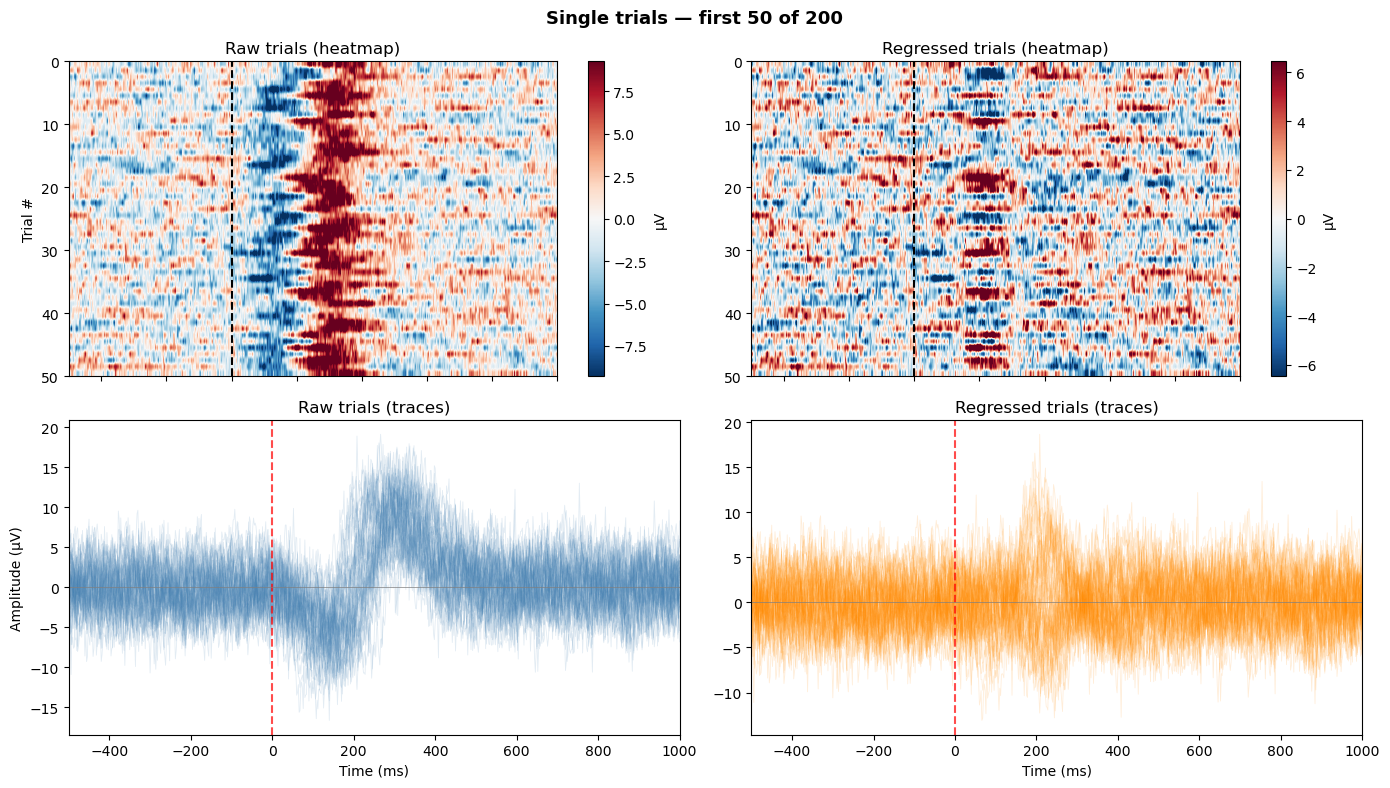

In [6]:
# Single trials before and after regression
n_show = min(n_trials, 50)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for col, (data, label, color) in enumerate([(trials, 'Raw', 'steelblue'),
                                            (trials_regressed, 'Regressed', 'darkorange')]):
    vmax = np.percentile(np.abs(data[:n_show]), 95)
    im = axes[0, col].imshow(data[:n_show], aspect='auto', origin='upper',
                             extent=[tmin * 1000, tmax * 1000, n_show, 0],
                             cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    axes[0, col].axvline(0, color='k', linestyle='--', linewidth=1.5)
    axes[0, col].set_title(f'{label} trials (heatmap)')
    plt.colorbar(im, ax=axes[0, col], label='µV')

    axes[1, col].plot(times * 1000, data[:n_show].T, color=color, alpha=0.15, linewidth=0.6)
    axes[1, col].axvline(0, color='r', linestyle='--', alpha=0.7)
    axes[1, col].axhline(0, color='gray', linewidth=0.5)
    axes[1, col].set_xlabel('Time (ms)')
    axes[1, col].set_title(f'{label} trials (traces)')
axes[0, 0].set_ylabel('Trial #')
axes[1, 0].set_ylabel('Amplitude (µV)')
fig.suptitle(f'Single trials — first {n_show} of {n_trials}', fontsize=13, fontweight='bold')
plt.tight_layout()

## 4. Woody alignment

Iteratively cross-correlate each trial with the current average, shift it by the lag that maximises the correlation, recompute the average, and repeat until the lags converge.

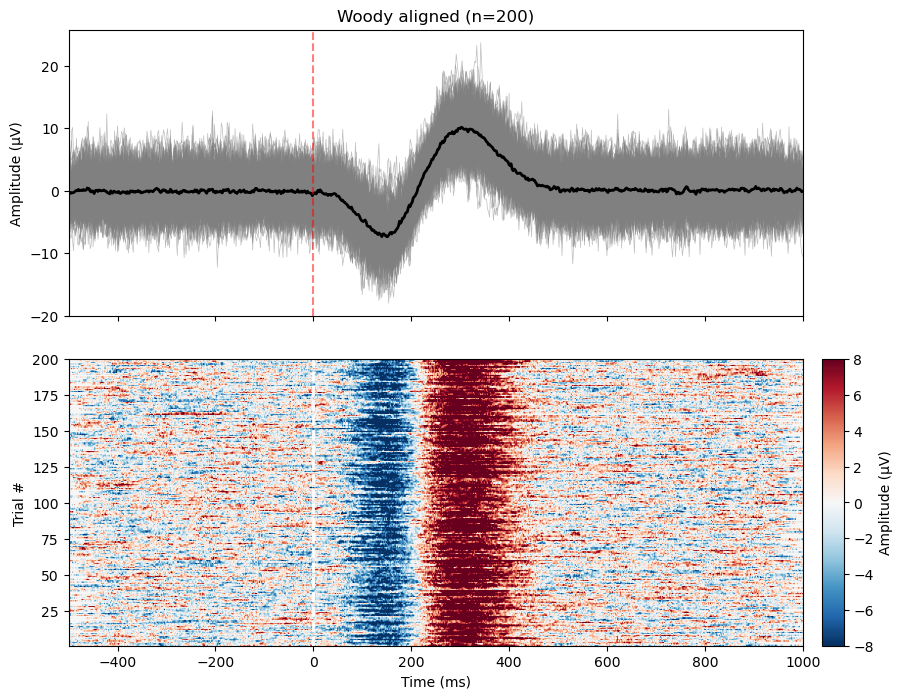

In [7]:
_, lags_woody = woody(trials.T, est_mthd='woody', **WOODY_KW)
aligned_woody = align_trials(trials, lags_woody)

plot_trials(times, aligned_woody, f'Woody aligned (n={n_trials})', vlim=8, trace_alpha=0.5);

Correlation true vs detected lags: 0.665


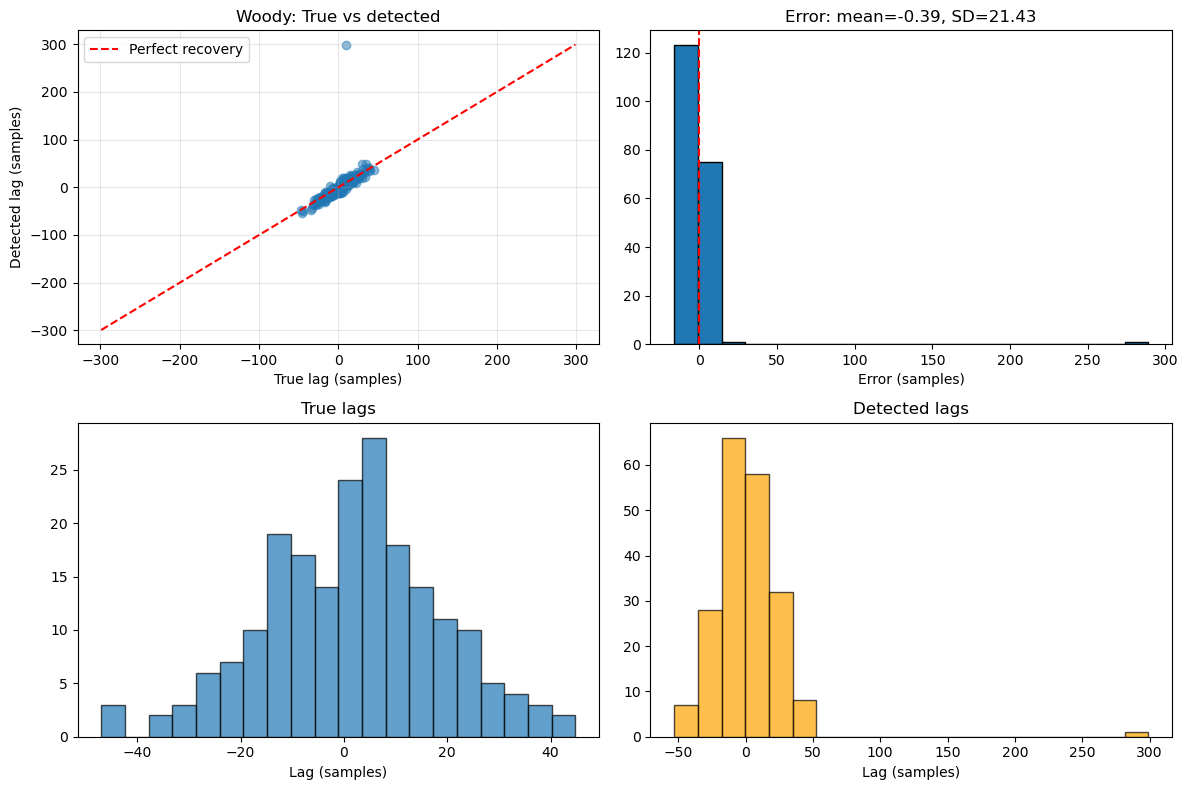

In [8]:
plot_lag_recovery(true_lags, lags_woody, 'Woody: ');

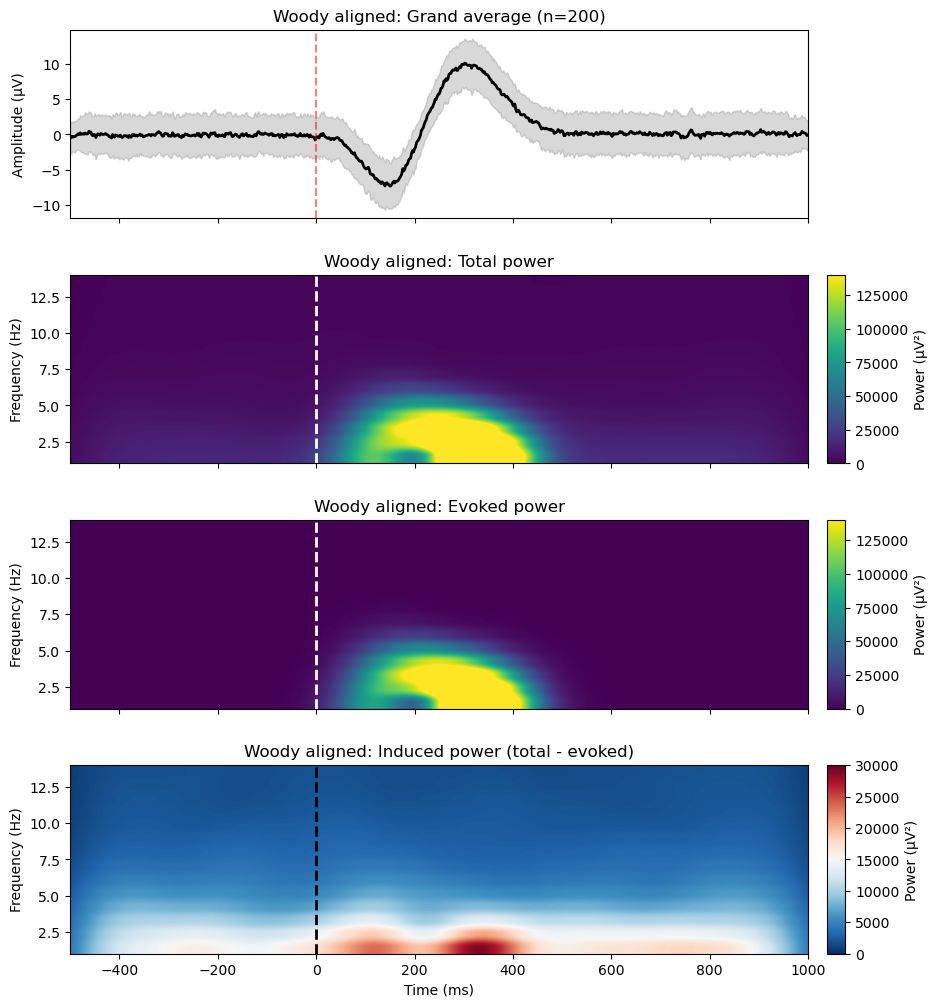

In [9]:
plot_tf_decomposition(times, freqs, aligned_woody,
                      compute_tfr(aligned_woody, freqs, sfreq),
                      compute_tfr(aligned_woody.mean(axis=0), freqs, sfreq),
                      prefix='Woody aligned: ');

## 5. Stochastic Woody alignment

Woody can get stuck in local optima at low SNR. The stochastic variant restarts it from `N_STOCH_RUNS` random initial lag offsets and keeps the solution with the highest mean trial-template correlation.

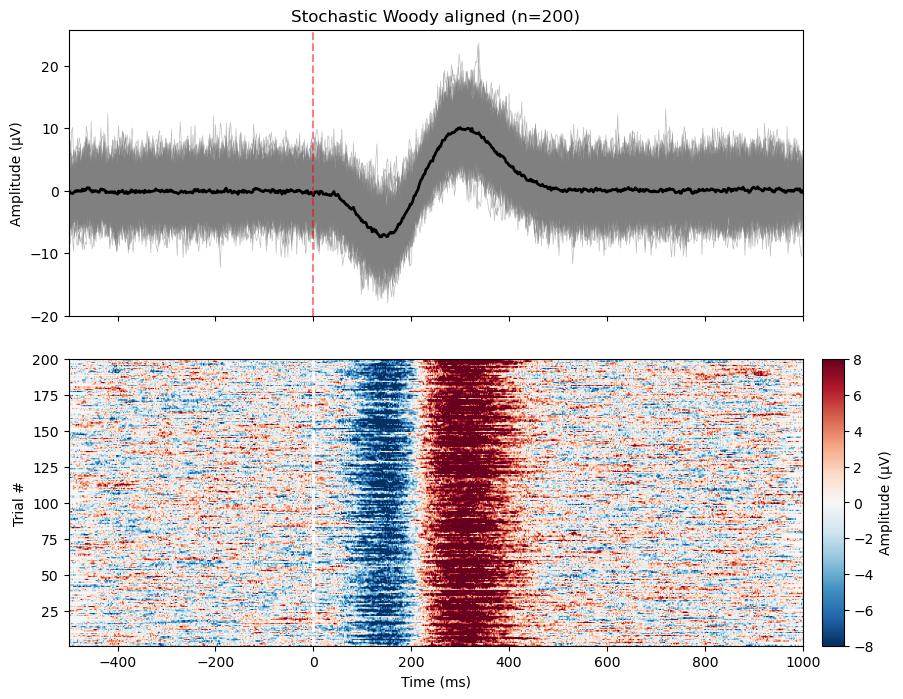

In [10]:
_, lags_stoch, _ = woody_stochastic(trials.T, n_runs=N_STOCH_RUNS, max_lag_init=10,
                                    max_shift=50, rng=rng, **WOODY_KW)
aligned_stoch = align_trials(trials, lags_stoch)

plot_trials(times, aligned_stoch, f'Stochastic Woody aligned (n={n_trials})', vlim=8, trace_alpha=0.5);

Correlation true vs detected lags: 0.951


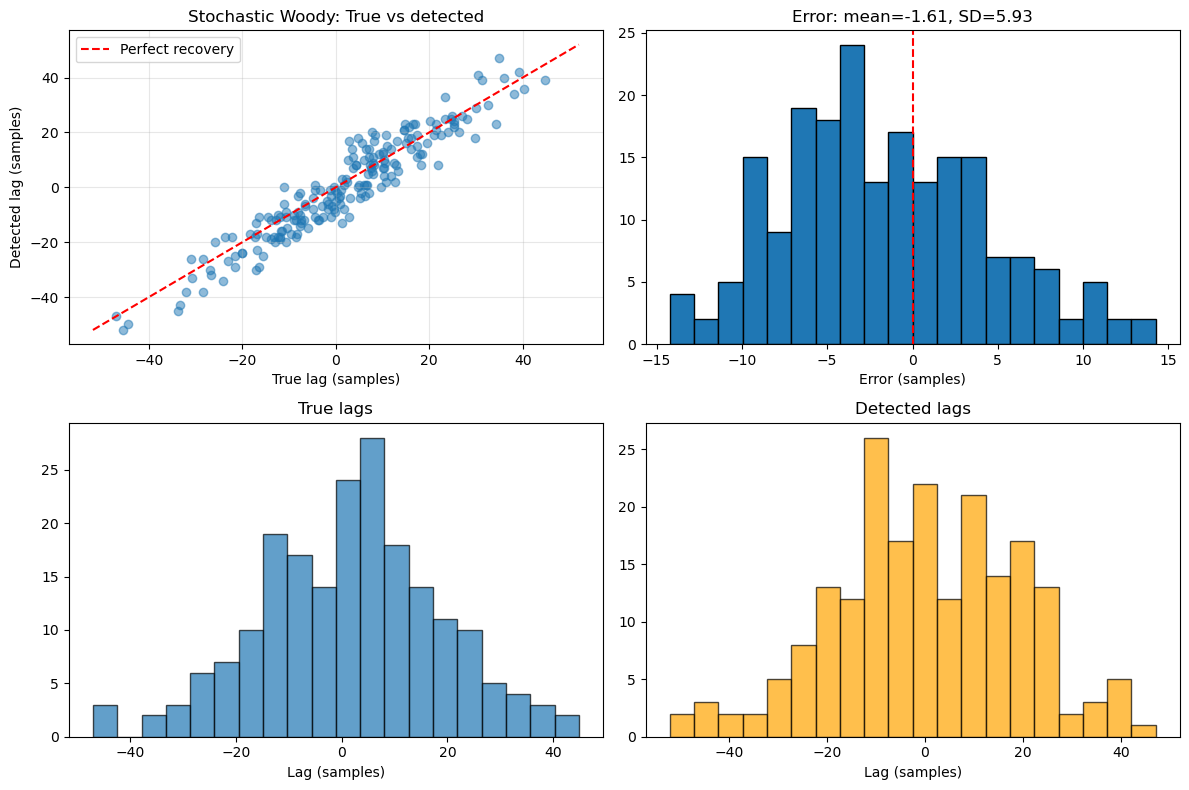

In [11]:
plot_lag_recovery(true_lags, lags_stoch, 'Stochastic Woody: ');

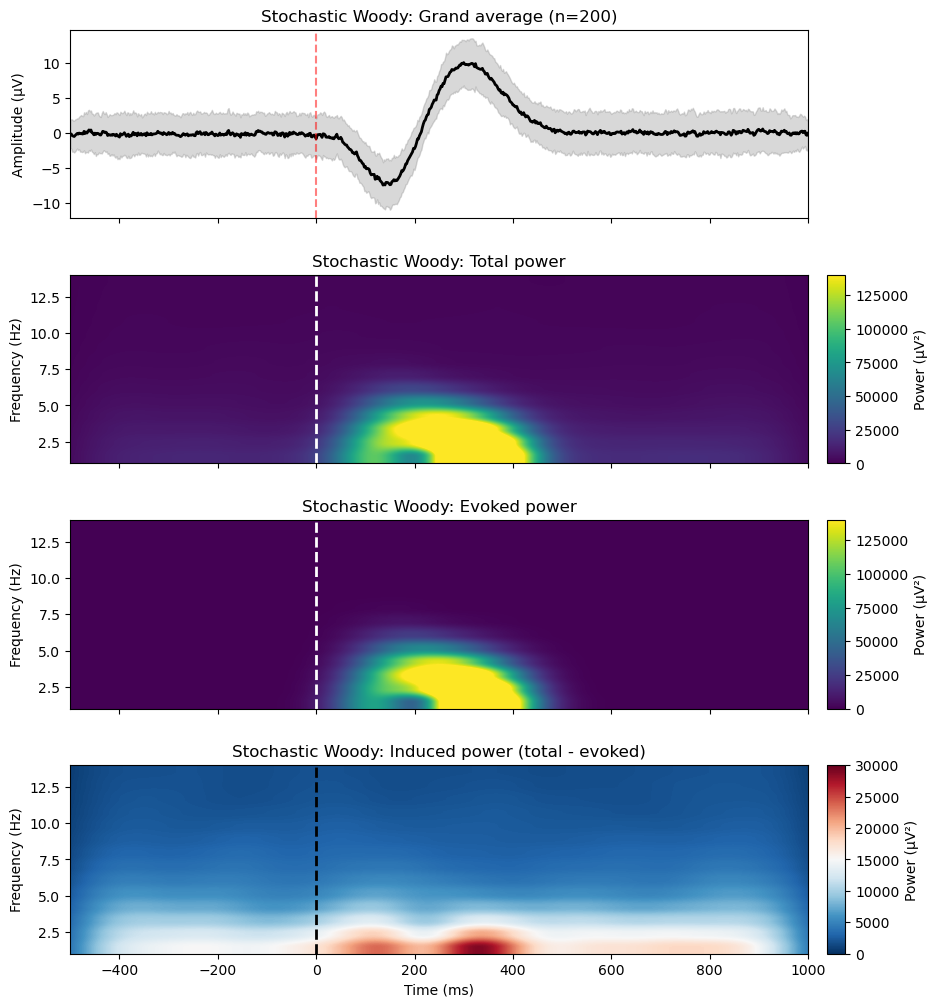

In [12]:
plot_tf_decomposition(times, freqs, aligned_stoch,
                      compute_tfr(aligned_stoch, freqs, sfreq),
                      compute_tfr(aligned_stoch.mean(axis=0), freqs, sfreq),
                      prefix='Stochastic Woody: ');

## 6. Stochastic Woody + ERP regression (+ reinstated lags)

Regress the *aligned* average out of each *aligned* trial, then shift the residuals back by their original lags so that any genuine post-event activity returns to its true event time (poster: *"Incorrect trials – ERP regressed out + Woody filtering"*). → **The spurious theta is gone.**

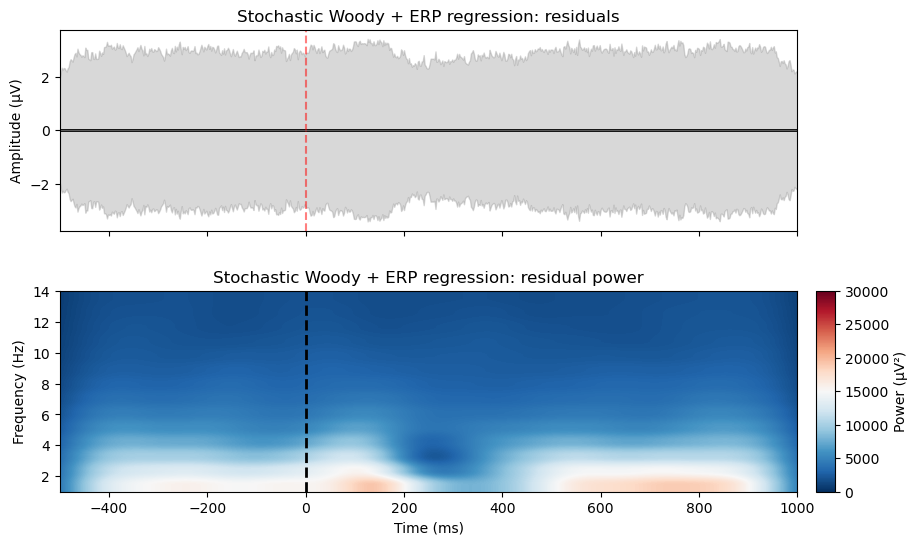

In [13]:
residuals_stoch = regress_erp(aligned_stoch, aligned_stoch.mean(axis=0))
plot_residual_tfr(times, freqs, residuals_stoch, compute_tfr(residuals_stoch, freqs, sfreq),
                  'Stochastic Woody + ERP regression');

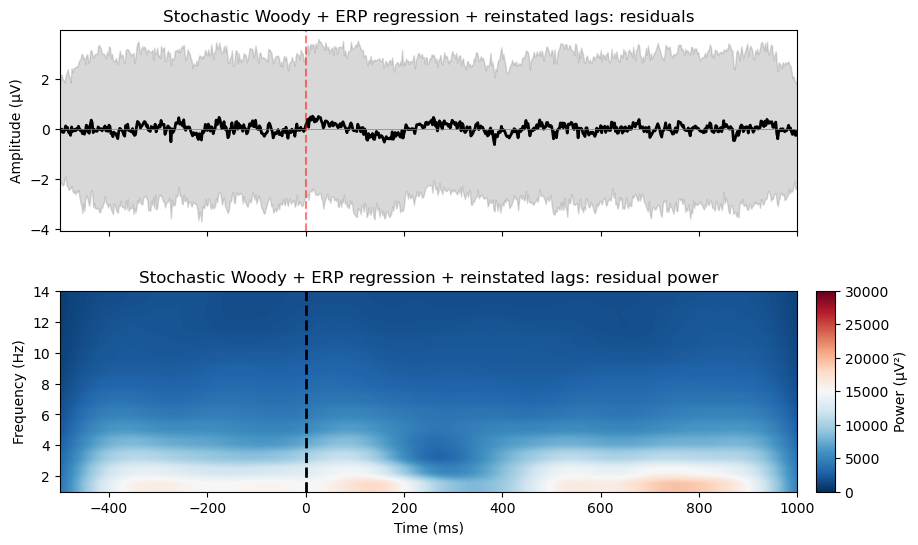

In [14]:
residuals_reinstated = reinstate_lags(residuals_stoch, lags_stoch)
plot_residual_tfr(times, freqs, residuals_reinstated,
                  compute_tfr(residuals_reinstated, freqs, sfreq),
                  'Stochastic Woody + ERP regression + reinstated lags');